In [35]:
# =============================================================================
# Projeto de Inteligência Artificial - 7ºJ SI Noite
# Predição de Hospitalização em Casos Confirmados de Dengue (SP)
#
# Integrantes do grupo:
#   - Geovanna da Silva Lima - RA: 10420059
#   - Pedro Henrique Mansano Fernandes - RA: 10388037
#   - Priscila Raquel Herculano Correia - RA: 10420400
#
# Síntese do conteúdo do arquivo:
#   Notebook de Modelagem, Avaliação e Análise de Equidade para o
#   problema de predição de hospitalização em pacientes com dengue
#   confirmada, utilizando dados públicos do SINAN/DATASUS (UF: SP).
# Histórico de alterações:
#   | Data       | Autor                    | Descrição                                     |
#   |------------|--------------------------|-----------------------------------------------|
#   | 2026-11-11 | Pedro Henrique           | Criação inicial do notebook                   |
# ==========================================================================================|

# Predição de Hospitalização em Casos Confirmados de Dengue — Modelagem (N2)

Continuação do `analise_exploratoria_dengue.ipynb` (N1), que gerou
`dengue_sp_treino.csv` (32.000 casos) e `dengue_sp_teste.csv` (8.000 casos),
ambos com ~4,7% de hospitalizados.

**Protocolo de avaliação:**

1. Modelo, hiperparâmetros e **limiar de decisão** são escolhidos **só no treino**,
   com validação cruzada estratificada (5 partições).
2. O teste é usado **uma única vez**, ao final, com intervalos de confiança por
   *bootstrap*.
3. O pré-processamento fica dentro de um `Pipeline`, evitando vazamento de
   informação entre as partições.

**Métricas:** com ~95% de negativos, a acurácia é enganosa (prever sempre "não
hospitalizado" acerta 95%). Usamos AUC-ROC, AUC-PR (*average precision*),
recall, precisão e F1 da classe positiva, priorizando o recall pelo custo de um
falso negativo em contexto clínico.

## 1. Configuração do ambiente

In [2]:
# Bibliotecas: pandas/numpy (dados), matplotlib/seaborn (gráficos),
# scikit-learn (modelos, validação e métricas).
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
                                     cross_val_predict, cross_validate)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", 100)

In [3]:
# >>> PREENCHER AQUI: caminhos e parâmetros <<<
# BASE_DIR aponta para a pasta dengue_IA/, seja o notebook executado a partir
# de notebooks/ (padrão do Jupyter/VS Code) ou da raiz do projeto.
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TREINO_PATH = BASE_DIR / "notebooks" / "dengue_sp_treino.csv"
TESTE_PATH = BASE_DIR / "notebooks" / "dengue_sp_teste.csv"

SEED = 42            # mesma semente do notebook de EDA
N_FOLDS = 5          # partições da validação cruzada
META_RECALL = 0.80   # recall mínimo desejado para a classe "hospitalizado"
N_BOOTSTRAP = 1000   # reamostragens para os intervalos de confiança

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

## 2. Carregamento dos dados preparados

In [4]:
# Categóricas lidas como texto para preservar os códigos do SINAN (ex.: "9" = ignorado)
CATEGORICAS = ["CS_SEXO", "CS_GESTANT", "CS_RACA", "CS_ESCOL_N"]
tipos = {c: str for c in CATEGORICAS}

treino = pd.read_csv(TREINO_PATH, dtype=tipos)
teste = pd.read_csv(TESTE_PATH, dtype=tipos)

ALVO = "HOSPITALIZ"
X_train, y_train = treino.drop(columns=ALVO), treino[ALVO]
X_test, y_test = teste.drop(columns=ALVO), teste[ALVO]

for nome, y in [("Treino", y_train), ("Teste", y_test)]:
    print(f"{nome}: {len(y):,} casos | {y.sum():,} hospitalizados ({y.mean() * 100:.2f}%)")

Treino: 32,000 casos | 1,509 hospitalizados (4.72%)
Teste: 8,000 casos | 377 hospitalizados (4.71%)


## 3. Pré-processamento

- **Categóricas** (`CS_SEXO`, `CS_GESTANT`, `CS_RACA`, `CS_ESCOL_N`): *one-hot*,
  com uma categoria de referência por variável (feminino, não gestante, branca,
  ensino médio completo), para que os coeficientes da Regressão Logística sejam
  lidos como "risco relativo à referência".
- **Numéricas** (`IDADE_ANOS`, `DIAS`): padronização.
- **Binárias** (14 sinais clínicos e 7 comorbidades): mantidas como 0/1.

In [5]:
NUMERICAS = ["IDADE_ANOS", "DIAS"]
BINARIAS = [c for c in X_train.columns if c not in CATEGORICAS + NUMERICAS]
REFERENCIAS = {"CS_SEXO": "F", "CS_GESTANT": "5", "CS_RACA": "1", "CS_ESCOL_N": "6"}

# Rótulos legíveis dos códigos do SINAN (dicionário de dados)
ROTULOS = {
    "CS_SEXO": {"F": "Feminino", "M": "Masculino"},
    "CS_GESTANT": {"1": "1º trimestre", "2": "2º trimestre", "3": "3º trimestre",
                   "4": "Idade gestacional ignorada", "5": "Não gestante",
                   "6": "Não se aplica", "9": "Ignorado"},
    "CS_RACA": {"1": "Branca", "2": "Preta", "3": "Amarela", "4": "Parda",
                "5": "Indígena", "9": "Ignorado"},
    "CS_ESCOL_N": {"0": "Analfabeto", "1": "1ª-4ª série incompleta",
                   "2": "4ª série completa", "3": "5ª-8ª série incompleta",
                   "4": "Fundamental completo", "5": "Médio incompleto",
                   "6": "Médio completo", "7": "Superior incompleto",
                   "8": "Superior completo", "9": "Ignorado",
                   "10": "Não se aplica", "99": "Não preenchido"},
}


def cria_pipeline(modelo, colunas=None):
    """Pipeline pré-processamento + modelo para o subconjunto `colunas` (usado na ablação)."""
    colunas = list(X_train.columns) if colunas is None else colunas
    cat = [c for c in CATEGORICAS if c in colunas]
    pre = ColumnTransformer([
        ("cat", OneHotEncoder(drop=[REFERENCIAS[c] for c in cat],
                              handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler(), [c for c in NUMERICAS if c in colunas]),
        ("bin", "passthrough", [c for c in BINARIAS if c in colunas]),
    ])
    return Pipeline([("pre", pre), ("modelo", modelo)])

## 4. Treinamento, comparação e ajuste dos modelos

Comparamos um **classificador trivial** (sorteia a classe na proporção
observada) com três modelos do *scikit-learn*: **Regressão Logística**,
**Random Forest** e **Gradient Boosting** (`HistGradientBoostingClassifier`).

O desbalanceamento é tratado com **ponderação de classes**
(`class_weight="balanced"`): erros na classe minoritária pesam ~20× mais no
treino. Em testes preliminares, essa estratégia foi igual ou melhor que a
subamostragem da classe majoritária, sem descartar dados.

Os hiperparâmetros são ajustados por busca aleatória (`RandomizedSearchCV`),
usando a **AUC-PR** como critério.

In [6]:
espacos = {
    "Regressão Logística": (
        LogisticRegression(class_weight="balanced", max_iter=3000),
        {"modelo__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
        9,
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, n_jobs=1, random_state=SEED),
        {"modelo__max_depth": [None, 8, 12, 16],
         "modelo__min_samples_leaf": [5, 10, 20, 50, 100],
         "modelo__max_features": ["sqrt", 0.3, 0.5],
         "modelo__class_weight": ["balanced", "balanced_subsample"]},
        15,
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
        {"modelo__learning_rate": [0.02, 0.05, 0.1],
         "modelo__max_leaf_nodes": [7, 15, 31, 63],
         "modelo__min_samples_leaf": [20, 50, 100, 200],
         "modelo__l2_regularization": [0.0, 0.1, 1.0],
         "modelo__max_iter": [200, 400]},
        20,
    ),
}

buscas = {}
for nome, (modelo, grade, n_iter) in espacos.items():
    busca = RandomizedSearchCV(cria_pipeline(modelo), grade, n_iter=n_iter,
                               scoring="average_precision", cv=cv, n_jobs=-1,
                               random_state=SEED, refit=True)
    buscas[nome] = busca.fit(X_train, y_train)
    print(f"{nome}: { {k.replace('modelo__', ''): v for k, v in busca.best_params_.items()} }")

Regressão Logística: {'C': 3}


Random Forest: {'min_samples_leaf': 20, 'max_features': 'sqrt', 'max_depth': 16, 'class_weight': 'balanced'}


Gradient Boosting: {'min_samples_leaf': 20, 'max_leaf_nodes': 7, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 1.0}


In [7]:
# Validação cruzada (treino) dos modelos ajustados vs. classificador trivial
METRICAS = {"AUC-ROC": "roc_auc", "AUC-PR": "average_precision", "Recall": "recall",
            "Precisão": "precision", "F1": "f1", "Acurácia": "accuracy"}

modelos_cv = {"Trivial (estratificado)": cria_pipeline(DummyClassifier(strategy="stratified", random_state=SEED))}
modelos_cv.update({nome: b.best_estimator_ for nome, b in buscas.items()})

tabela = {}
for nome, pipe in modelos_cv.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=METRICAS, n_jobs=-1)
    tabela[nome] = {m: f"{r[f'test_{m}'].mean():.3f} ± {r[f'test_{m}'].std():.3f}" for m in METRICAS}
print("Média ± desvio nas 5 partições (limiar padrão 0,5)")
pd.DataFrame(tabela).T

Média ± desvio nas 5 partições (limiar padrão 0,5)


,AUC-ROC,AUC-PR,Recall,Precisão,F1,Acurácia
Trivial (estratificado),0.501 ± 0.003,0.047 ± 0.000,0.051 ± 0.005,0.050 ± 0.005,0.050 ± 0.005,0.909 ± 0.000
Regressão Logística,0.735 ± 0.020,0.139 ± 0.020,0.625 ± 0.040,0.102 ± 0.005,0.175 ± 0.009,0.723 ± 0.003
Random Forest,0.757 ± 0.015,0.181 ± 0.025,0.637 ± 0.035,0.113 ± 0.005,0.192 ± 0.008,0.748 ± 0.005
Gradient Boosting,0.753 ± 0.011,0.183 ± 0.023,0.664 ± 0.030,0.109 ± 0.004,0.188 ± 0.006,0.729 ± 0.005


In [8]:
# Modelo final = maior AUC-PR média na validação cruzada (critério definido a priori)
NOME_FINAL = max(buscas, key=lambda n: buscas[n].best_score_)
modelo_final = buscas[NOME_FINAL].best_estimator_
print(f"Modelo escolhido: {NOME_FINAL}")

Modelo escolhido: Gradient Boosting


- Os três modelos superam com folga o classificador trivial (AUC-ROC de 0,74 a
  0,76 vs. 0,50; AUC-PR de 0,14 a 0,18 vs. 0,047).
- Random Forest e Gradient Boosting praticamente empatam e superam a Regressão
  Logística em AUC-PR, por captarem a relação **não linear** de `DIAS` (EDA,
  seção 5.4). O **Gradient Boosting** tem a maior AUC-PR e é o modelo final.
- A acurácia dos modelos (~0,73) é *menor* que a do trivial que prevê sempre
  "não" (0,953): o modelo troca acertos fáceis na classe majoritária por
  identificar hospitalizações.

## 5. Escolha do limiar de decisão

O limiar padrão de 0,5 é arbitrário. Escolhemos o limiar que atinge
**recall ≥ 80%** com a maior precisão possível, usando probabilidades
*out-of-fold* do **treino** (cada caso é previsto por um modelo que não o viu).

In [9]:
def escolhe_limiar(y, proba, meta_recall):
    """Maior precisão entre os limiares com recall >= meta_recall."""
    precisoes, recalls, limiares = precision_recall_curve(y, proba)
    ok = recalls[:-1] >= meta_recall
    return limiares[ok][np.argmax(precisoes[:-1][ok])]


proba_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]
LIMIAR = escolhe_limiar(y_train, proba_oof, META_RECALL)
print(f"Limiar escolhido (meta de recall {META_RECALL:.0%}): {LIMIAR:.3f}")

# Custo de cada meta de recall (treino, out-of-fold)
pontos = {}
for meta in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = proba_oof >= escolhe_limiar(y_train, proba_oof, meta)
    pontos[f"{meta:.0%}"] = {"Recall": recall_score(y_train, pred),
                             "Precisão": precision_score(y_train, pred),
                             "% sinalizados": pred.mean() * 100}
pd.DataFrame(pontos).T.rename_axis("Meta de recall").round(3)

Limiar escolhido (meta de recall 80%): 0.365


,Recall,Precisão,% sinalizados
Meta de recall,,,
50%,0.501,0.145,16.322
60%,0.600,0.120,23.519
70%,0.702,0.097,34.000
80%,0.801,0.078,48.419
90%,0.901,0.061,69.581


Recall de 80% custa caro: ~48% dos pacientes são sinalizados, com precisão de
~8% (ainda 1,7× a prevalência). A escolha do ponto de operação é uma decisão
clínica e de gestão; mantemos 80% pela prioridade, declarada no relatório, de
evitar falsos negativos.

## 6. Avaliação final no conjunto de teste

In [10]:
def metricas_teste(y, proba, limiar):
    pred = (proba >= limiar).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"AUC-ROC": roc_auc_score(y, proba), "AUC-PR": average_precision_score(y, proba),
            "Limiar": limiar, "Recall": tp / (tp + fn), "Precisão": tp / (tp + fp) if tp + fp else 0.0,
            "F1": f1_score(y, pred), "Acurácia": (tp + tn) / len(y), "% sinalizados": pred.mean() * 100}


probas_teste = {nome: pipe.fit(X_train, y_train).predict_proba(X_test)[:, 1] if nome.startswith("Trivial")
                else pipe.predict_proba(X_test)[:, 1] for nome, pipe in modelos_cv.items()}

linhas = {f"{n} (limiar 0,5)": metricas_teste(y_test, p, 0.5) for n, p in probas_teste.items()}
linhas[f"{NOME_FINAL} (limiar escolhido)"] = metricas_teste(y_test, probas_teste[NOME_FINAL], LIMIAR)
pd.DataFrame(linhas).T.round(3)

,AUC-ROC,AUC-PR,Limiar,Recall,Precisão,F1,Acurácia,% sinalizados
"Trivial (estratificado) (limiar 0,5)",0.489,0.047,0.500,0.024,0.025,0.024,0.910,4.538
"Regressão Logística (limiar 0,5)",0.730,0.128,0.500,0.637,0.102,0.176,0.718,29.438
"Random Forest (limiar 0,5)",0.750,0.167,0.500,0.629,0.115,0.195,0.755,25.688
"Gradient Boosting (limiar 0,5)",0.760,0.171,0.500,0.663,0.115,0.196,0.744,27.175
Gradient Boosting (limiar escolhido),0.760,0.171,0.365,0.801,0.081,0.147,0.562,46.588


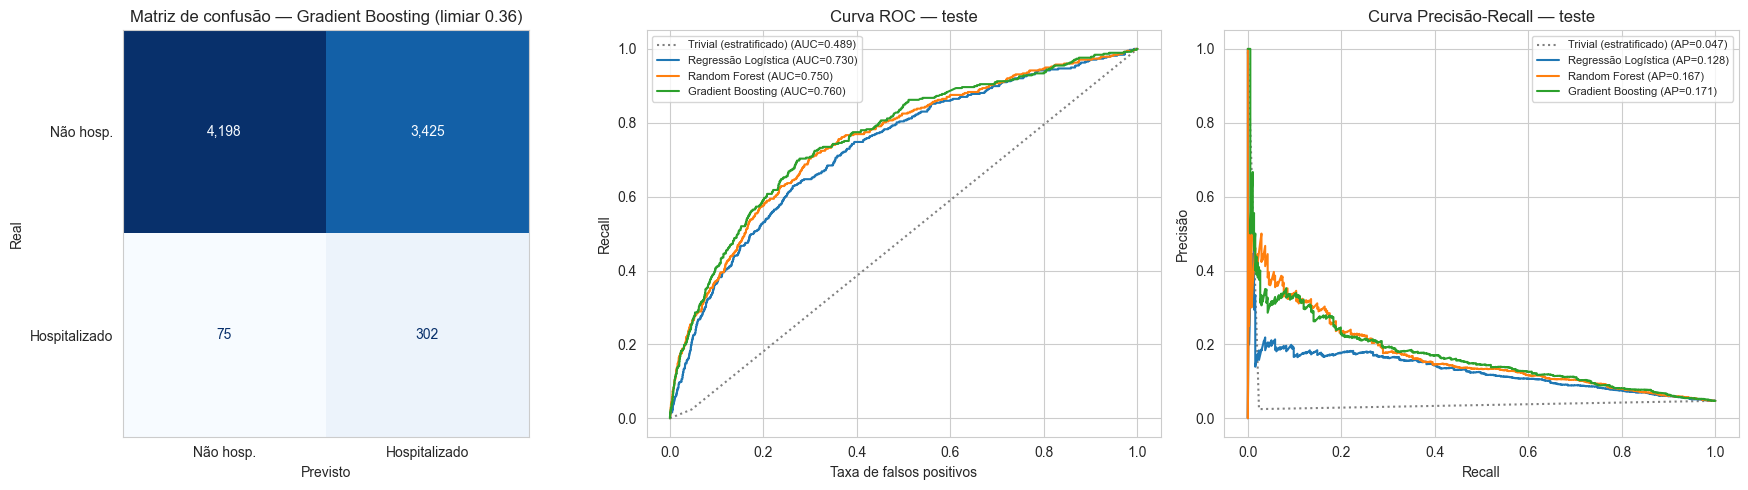

In [11]:
proba_final = probas_teste[NOME_FINAL]
pred_final = (proba_final >= LIMIAR).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_final, display_labels=["Não hosp.", "Hospitalizado"],
    cmap="Blues", values_format=",", ax=axes[0], colorbar=False)
axes[0].set(title=f"Matriz de confusão — {NOME_FINAL} (limiar {LIMIAR:.2f})",
            xlabel="Previsto", ylabel="Real")
axes[0].grid(False)

for nome, proba in probas_teste.items():
    estilo = {"ls": ":", "color": "gray"} if nome.startswith("Trivial") else {}
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[1].plot(fpr, tpr, label=f"{nome} (AUC={roc_auc_score(y_test, proba):.3f})", **estilo)
    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[2].plot(rec, prec, label=f"{nome} (AP={average_precision_score(y_test, proba):.3f})", **estilo)
axes[1].set(xlabel="Taxa de falsos positivos", ylabel="Recall", title="Curva ROC — teste")
axes[2].set(xlabel="Recall", ylabel="Precisão", title="Curva Precisão-Recall — teste")
for ax in axes[1:]:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [12]:
# Intervalos de confiança de 95% por bootstrap (reamostragem do teste com reposição)
rng = np.random.RandomState(SEED)
y_arr, proba_lr = y_test.to_numpy(), probas_teste["Regressão Logística"]
amostras = []
for _ in range(N_BOOTSTRAP):
    idx = rng.randint(0, len(y_arr), len(y_arr))
    yb, pb, predb = y_arr[idx], proba_final[idx], pred_final[idx]
    amostras.append({"AUC-ROC": roc_auc_score(yb, pb), "AUC-PR": average_precision_score(yb, pb),
                     "Recall": recall_score(yb, predb), "Precisão": precision_score(yb, predb),
                     "Δ AUC-PR vs. Reg. Logística": average_precision_score(yb, pb)
                                                    - average_precision_score(yb, proba_lr[idx])})
amostras = pd.DataFrame(amostras)

pontual = metricas_teste(y_test, proba_final, LIMIAR)
pontual["Δ AUC-PR vs. Reg. Logística"] = pontual["AUC-PR"] - average_precision_score(y_test, proba_lr)
pd.DataFrame({"Estimativa": {m: pontual[m] for m in amostras.columns},
              "IC 95% inf.": amostras.quantile(0.025),
              "IC 95% sup.": amostras.quantile(0.975)}).round(3)

,Estimativa,IC 95% inf.,IC 95% sup.
AUC-ROC,0.760,0.731,0.785
AUC-PR,0.171,0.142,0.206
Recall,0.801,0.757,0.841
Precisão,0.081,0.072,0.090
Δ AUC-PR vs. Reg. Logística,0.043,0.022,0.064


- **Sem sobreajuste:** o teste confirma a validação cruzada (AUC-ROC de 0,760 vs.
  0,753).
- **Superior ao acaso e à Regressão Logística, com significância:** a AUC-ROC
  tem IC de 0,731 a 0,785 (bem acima de 0,5), e a diferença de AUC-PR para a
  Regressão Logística tem IC de 0,022 a 0,064, que não inclui zero.
- **No limiar escolhido:** o modelo identifica 302 dos 377 hospitalizados
  (recall de 0,80, confirmando a meta) e sinaliza 46,6% dos pacientes, com
  precisão de 0,08. Entre os não sinalizados, só 1,8% foram hospitalizados
  (contra 4,7% no geral).
- **Discriminação moderada:** a ficha do SINAN não traz sinais vitais, plaquetas
  ou hematócrito, principais determinantes da internação.

## 7. Interpretabilidade

- **Razões de chances da Regressão Logística:** quanto cada fator multiplica a
  chance de hospitalização. Para as numéricas, o efeito é expresso a cada 10 anos
  de idade e a cada 1 dia de `DIAS`.
- **Importância por permutação do modelo final:** quanto a AUC-PR no teste cai
  ao embaralhar cada variável.

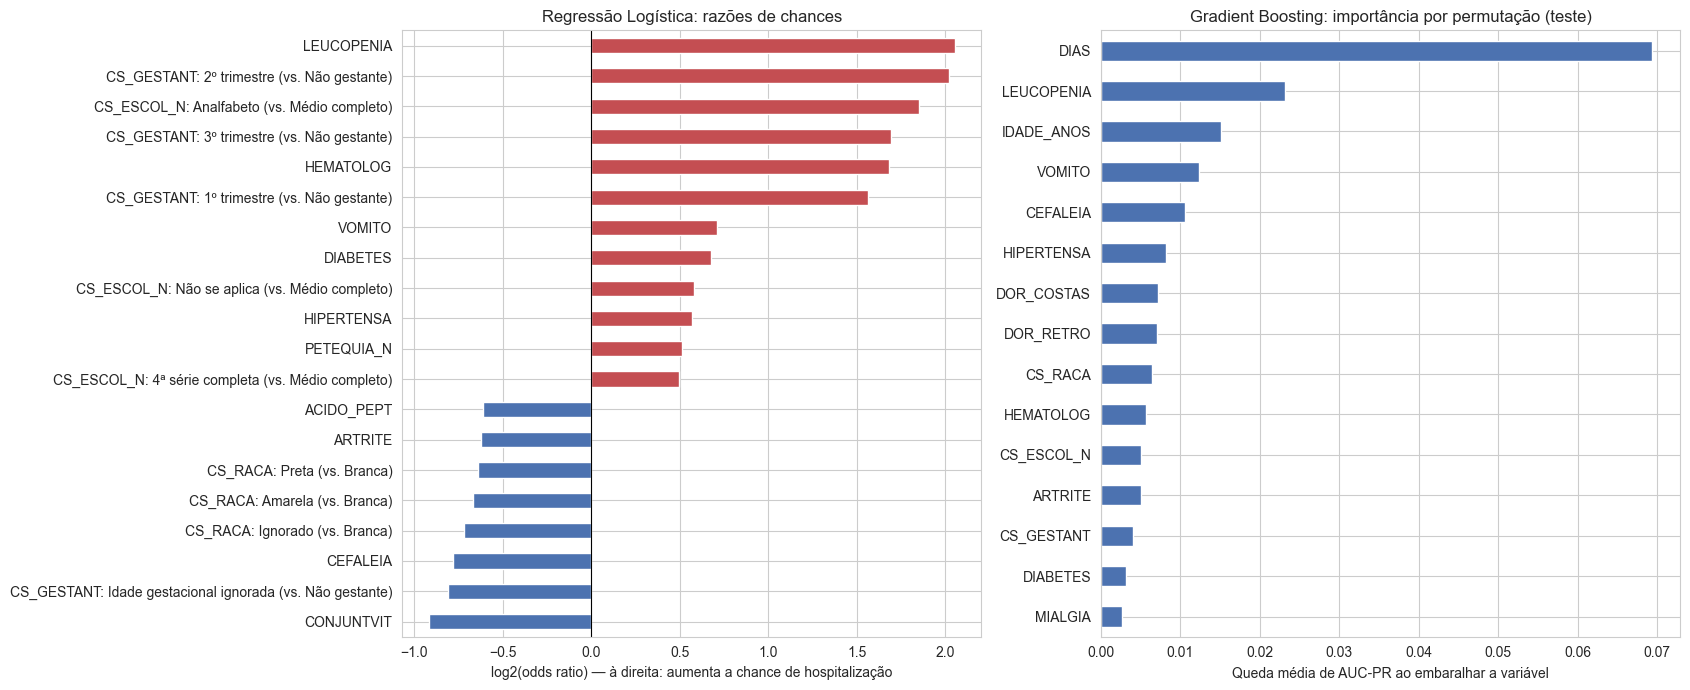

In [13]:
lr = buscas["Regressão Logística"].best_estimator_
pre, coef = lr.named_steps["pre"], lr.named_steps["modelo"].coef_[0]
escala = dict(zip(NUMERICAS, pre.named_transformers_["num"].scale_))
unidade = {"IDADE_ANOS": (10, "anos"), "DIAS": (1, "dia")}

odds = {}
for nome, b in zip(pre.get_feature_names_out(), coef):
    grupo, var = nome.split("__", 1)
    if grupo == "num":
        n, u = unidade[var]
        odds[f"{var} (+{n} {u})"] = np.exp(b / escala[var] * n)
    elif grupo == "cat":
        col, cod = var.rsplit("_", 1)
        odds[f"{col}: {ROTULOS[col].get(cod, cod)} (vs. {ROTULOS[col][REFERENCIAS[col]]})"] = np.exp(b)
    else:
        odds[var] = np.exp(b)
odds = pd.Series(odds).sort_values()
imp = permutation_importance(modelo_final, X_test, y_test, scoring="average_precision",
                             n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))
destaque = pd.concat([odds.head(8), odds.tail(12)])
np.log2(destaque).plot(kind="barh", ax=axes[0],
                       color=["#4C72B0" if v < 1 else "#C44E52" for v in destaque])
axes[0].axvline(0, color="black", lw=0.8)
axes[0].set(xlabel="log2(odds ratio) — à direita: aumenta a chance de hospitalização",
            title="Regressão Logística: razões de chances")
imp.plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set(xlabel="Queda média de AUC-PR ao embaralhar a variável",
            title=f"{NOME_FINAL}: importância por permutação (teste)")
plt.tight_layout()
plt.show()

- **`DIAS` é a variável mais importante** para o Gradient Boosting, mas tem
  efeito pequeno na Regressão Logística: a relação é não linear (o risco sobe até
  ~2 semanas de doença e cai depois).
- **Fatores de risco esperados:** leucopenia, idade, vômito, hipertensão,
  diabetes, doença hematológica e gestação aumentam a chance de internação. No
  caso da gestação, isso reflete também a conduta assistencial, que dá
  acompanhamento diferenciado às gestantes.
- **Sintomas "clássicos" associados a menor chance:** cefaleia, dor
  retro-orbital, artrite e conjuntivite são típicos de casos leves. São
  associações, não efeitos causais.
- **Raça/cor:** as categorias não brancas aparecem com chance menor de
  internação, o que provavelmente reflete acesso a leitos, e não biologia. Ver a
  seção 9.

## 8. Ablação: `LEUCOPENIA` e `DIAS`

`LEUCOPENIA` vem de **hemograma**, que nem sempre está disponível no primeiro
atendimento e tende a ser pedido para pacientes mais graves (possível vazamento
parcial). `DIAS` pode refletir o momento da internação quando a notificação é
feita no hospital. Retreinamos o modelo final sem cada variável para medir sua
contribuição.

In [14]:
cenarios = {
    "Completo": list(X_train.columns),
    "Sem LEUCOPENIA": [c for c in X_train.columns if c != "LEUCOPENIA"],
    "Sem DIAS": [c for c in X_train.columns if c != "DIAS"],
    "Sem LEUCOPENIA e DIAS": [c for c in X_train.columns if c not in ("LEUCOPENIA", "DIAS")],
}
modelo_base = modelo_final.named_steps["modelo"]

ablacao = {}
for nome, cols in cenarios.items():
    pipe = cria_pipeline(clone(modelo_base), cols)
    r = cross_validate(pipe, X_train[cols], y_train, cv=cv, n_jobs=-1,
                       scoring={"AUC-ROC": "roc_auc", "AUC-PR": "average_precision"})
    proba = pipe.fit(X_train[cols], y_train).predict_proba(X_test[cols])[:, 1]
    ablacao[nome] = {"AUC-ROC (CV)": r["test_AUC-ROC"].mean(), "AUC-PR (CV)": r["test_AUC-PR"].mean(),
                     "AUC-ROC (teste)": roc_auc_score(y_test, proba),
                     "AUC-PR (teste)": average_precision_score(y_test, proba)}
pd.DataFrame(ablacao).T.round(3)

,AUC-ROC (CV),AUC-PR (CV),AUC-ROC (teste),AUC-PR (teste)
Completo,0.753,0.183,0.760,0.171
Sem LEUCOPENIA,0.739,0.162,0.745,0.174
Sem DIAS,0.709,0.150,0.711,0.136
Sem LEUCOPENIA e DIAS,0.685,0.122,0.687,0.133


- **`DIAS`** é a maior contribuição: sem ela, a AUC-ROC cai de 0,76 para 0,71.
- **`LEUCOPENIA`** tem contribuição moderada: sem ela, a AUC-PR cai 0,021 na
  validação cruzada e fica igual no teste (dentro da margem de incerteza).
- **Decisão do grupo: manter `LEUCOPENIA`.** Ela é informação plausível no
  atendimento de pacientes de risco, e o modelo não depende criticamente dela. A
  versão sem a variável é a alternativa para serviços sem hemograma no primeiro
  atendimento.

## 9. Análise de equidade entre subgrupos

Esta seção fornece a evidência numérica para a discussão de **aspectos éticos e
responsabilidade** apresentada no relatório (seção 3). Avaliamos, no teste e com
o limiar escolhido, se o modelo funciona de forma equilibrada entre **sexo**,
**raça/cor** e **faixa etária**:

- **recall**: dos hospitalizados do grupo, quantos o modelo identifica;
- **TFP** (taxa de falsos positivos): dos não hospitalizados, quantos são
  sinalizados.

Grupos com menos de 30 hospitalizados têm estimativas instáveis.

In [15]:
grupos = pd.DataFrame({
    "Sexo": X_test["CS_SEXO"].map(ROTULOS["CS_SEXO"]),
    "Raça/cor": X_test["CS_RACA"].map(ROTULOS["CS_RACA"]),
    "Faixa etária": pd.cut(X_test["IDADE_ANOS"], bins=[-1, 14, 39, 59, 200],
                           labels=["0-14", "15-39", "40-59", "60+"]).astype(str),
})


def metricas_grupo(mask, pred):
    y, p = y_test.to_numpy()[mask], pred[mask]
    return {"Casos": mask.sum(), "Hospitalizados": y.sum(), "Prevalência (%)": y.mean() * 100,
            "Sinalizados (%)": p.mean() * 100,
            "Recall": p[y == 1].mean() if y.sum() else np.nan,
            "TFP": p[y == 0].mean(),
            "AUC-ROC": roc_auc_score(y, proba_final[mask]) if 0 < y.sum() < len(y) else np.nan}


tab_eq = pd.concat({var: pd.DataFrame({g: metricas_grupo((grupos[var] == g).to_numpy(), pred_final)
                                       for g in sorted(grupos[var].unique())}).T
                    for var in grupos.columns})
tab_eq.loc[("Geral", "Todos"), :] = metricas_grupo(np.ones(len(y_test), bool), pred_final)
tab_eq.astype(float).round(3)

Casos  Hospitalizados  Prevalência (%)  \
Sexo         Feminino   4467.0           217.0            4.858   
             Masculino  3533.0           160.0            4.529   
Raça/cor     Amarela      76.0             3.0            3.947   
             Branca     4826.0           258.0            5.346   
             Ignorado   1050.0            30.0            2.857   
             Indígena      9.0             0.0            0.000   
             Parda      1701.0            74.0            4.350   
             Preta       338.0            12.0            3.550   
Faixa etária 0-14       1017.0            43.0            4.228   
             15-39      3392.0           115.0            3.390   
             40-59      2265.0           103.0            4.547   
             60+        1326.0           116.0            8.748   
Geral        Todos      8000.0           377.0            4.712   

                        Sinalizados (%)  Recall    TFP  AUC-ROC  
Sexo         Feminino            48.131   0.820  0.464    0.774  
             Masculino           44.636   0.775  0.431    0.740  
Raça/cor     Amarela             35.526   0.667  0.342    0.708  
             Branca              51.678   0.826  0.499    0.758  
             Ignorado            38.571   0.833  0.373    0.781  
             Indígena            66.667     NaN  0.667      NaN  
             Parda               39.918   0.757  0.383    0.769  
             Preta               34.320   0.500  0.337    0.584  
Faixa etária 0-14                47.591   0.791  0.462    0.753  
             15-39               32.164   0.696  0.309    0.751  
             40-59               45.916   0.728  0.446    0.723  
             60+                 83.861   0.974  0.826    0.740  
Geral        Todos               46.588   0.801  0.449    0.760

In [16]:
# Mesmo modelo sem CS_RACA (limiar escolhido da mesma forma, no treino)
cols_sem_raca = [c for c in X_train.columns if c != "CS_RACA"]
modelo_sem_raca = cria_pipeline(clone(modelo_base), cols_sem_raca)
oof_sr = cross_val_predict(modelo_sem_raca, X_train[cols_sem_raca], y_train, cv=cv,
                           method="predict_proba", n_jobs=-1)[:, 1]
limiar_sr = escolhe_limiar(y_train, oof_sr, META_RECALL)
proba_sr = modelo_sem_raca.fit(X_train[cols_sem_raca], y_train).predict_proba(X_test[cols_sem_raca])[:, 1]
pred_sr = (proba_sr >= limiar_sr).astype(int)
print(f"Sem CS_RACA: AUC-ROC teste = {roc_auc_score(y_test, proba_sr):.3f} "
      f"(com: {roc_auc_score(y_test, proba_final):.3f}) | "
      f"AUC-PR teste = {average_precision_score(y_test, proba_sr):.3f} "
      f"(com: {average_precision_score(y_test, proba_final):.3f})")

comparacao = {}
for g in ["Branca", "Parda", "Preta", "Ignorado", "Todos"]:
    m = np.ones(len(y_test), bool) if g == "Todos" else (grupos["Raça/cor"] == g).to_numpy()
    com, sem = metricas_grupo(m, pred_final), metricas_grupo(m, pred_sr)
    comparacao[g] = {"Sinalizados % (com raça)": com["Sinalizados (%)"],
                     "Sinalizados % (sem raça)": sem["Sinalizados (%)"],
                     "Recall (com raça)": com["Recall"], "Recall (sem raça)": sem["Recall"]}
pd.DataFrame(comparacao).T.round(3)

Sem CS_RACA: AUC-ROC teste = 0.752 (com: 0.760) | AUC-PR teste = 0.163 (com: 0.171)


,Sinalizados % (com raça),Sinalizados % (sem raça),Recall (com raça),Recall (sem raça)
Branca,51.678,49.399,0.826,0.814
Parda,39.918,45.032,0.757,0.811
Preta,34.320,39.053,0.500,0.500
Ignorado,38.571,51.905,0.833,0.933
Todos,46.588,48.325,0.801,0.812


- **Sexo:** desempenho equilibrado (recall de 0,82 no sexo feminino vs. 0,78 no
  masculino).
- **Faixa etária:** com um limiar único, o modelo sinaliza 84% dos idosos (60+) e
  32% dos adultos de 15 a 39 anos. A capacidade de ordenar o risco dentro de cada
  faixa é parecida (AUC-ROC de 0,72 a 0,75); a diferença vem das prevalências
  distintas (8,7% vs. 3,4%).
- **Raça/cor:** o modelo sinaliza 52% dos brancos e 40% dos pardos, com recall
  menor entre pardos (0,76 vs. 0,83). Se a menor taxa de internação observada
  entre pretos e pardos reflete **menor acesso** a leitos, o modelo reproduz essa
  desigualdade.
- **Sem `CS_RACA`:** a perda de desempenho é pequena (AUC-ROC de 0,760 para
  0,752). A diferença de sinalização entre brancos e pardos cai de 12 para 4
  pontos, e o recall dos pardos sobe para 0,81, igualando-se ao dos brancos. Para
  um uso prático, a versão sem raça/cor é a mais indicada.
- Os grupos preto, amarelo e indígena têm poucos hospitalizados no teste; suas
  estimativas são inconclusivas.

## 10. Conclusões

1. O **Gradient Boosting** foi o melhor modelo: **AUC-ROC de 0,760** (IC 95%:
   0,731–0,785) e **AUC-PR de 0,171** no teste, superior ao classificador
   trivial e à Regressão Logística.
2. Com o limiar escolhido no treino, o modelo identificou **80% dos
   hospitalizados**, sinalizando 47% dos pacientes (precisão de 8%). A acurácia
   (56%) é inadequada como métrica neste problema: o trivial atinge 95%.
3. As variáveis mais informativas foram **`DIAS`**, leucopenia, idade, vômito e
   comorbidades como hipertensão, diabetes e doença hematológica.
4. O modelo é equilibrado entre sexos, mas apresenta **disparidade por
   raça/cor**, atenuada pela remoção da variável com custo pequeno de
   desempenho.
5. **Limitações:**
   - a discriminação é moderada;
   - o desfecho reflete também a conduta médica e a disponibilidade de leitos;
   - `DIAS` e `LEUCOPENIA` podem ter sido registradas após o primeiro contato;
   - as probabilidades não estão calibradas;
   - os dados são apenas de SP em 2025.

O modelo é uma **ferramenta de apoio** à triagem e não substitui o julgamento
clínico.